Epoch    0 | Critic Loss: 6.9982 | Generator Loss: 0.0704


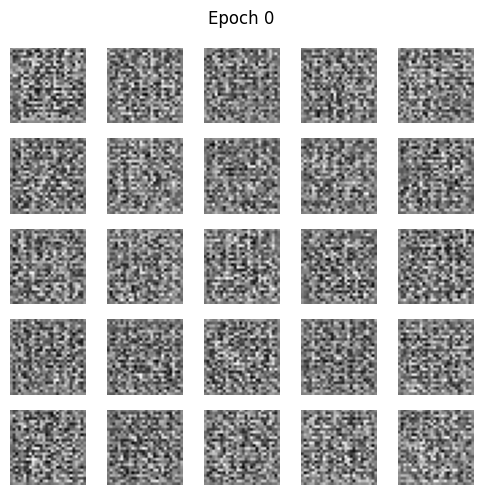

Epoch  500 | Critic Loss: -2.1072 | Generator Loss: -7.2128


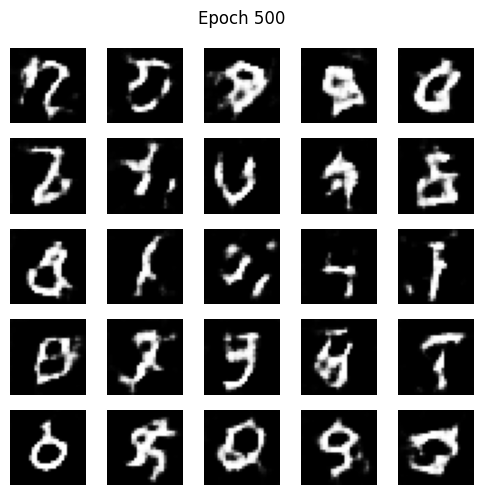

Epoch 1000 | Critic Loss: -1.4319 | Generator Loss: -5.2228


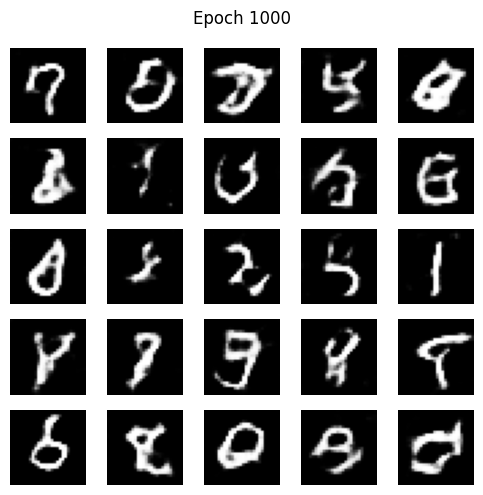

Epoch 1500 | Critic Loss: -1.7622 | Generator Loss: -6.0580


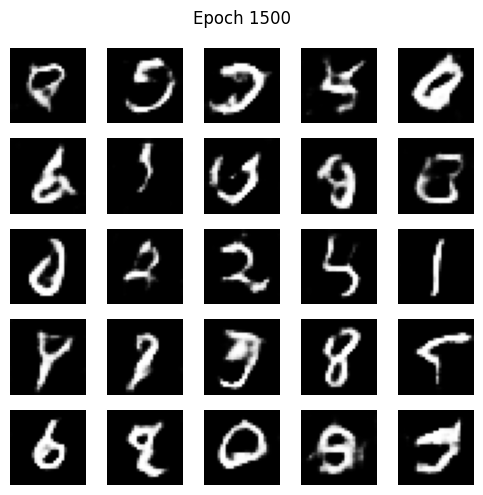

Epoch 2000 | Critic Loss: -2.1617 | Generator Loss: -1.3629


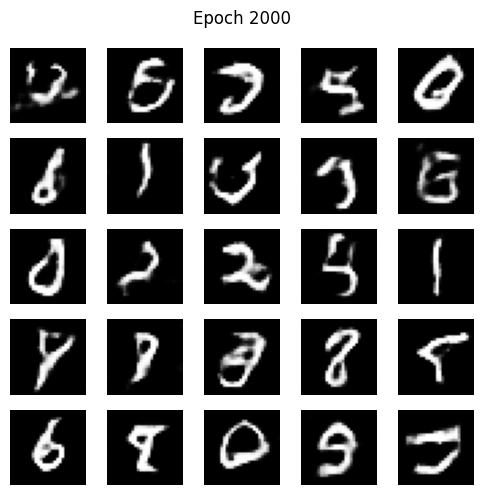

In [3]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Dense, Reshape, Flatten, LeakyReLU, ReLU,
    BatchNormalization, Conv2D, Conv2DTranspose
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()
x_train = (x_train.astype(np.float32) - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

LATENT_DIM = 100
LAMBDA_GP = 10.0
BATCH_SIZE = 64
LR = 0.0005
N_CRITIC = 3

def build_generator():
    inp = Input(shape=(LATENT_DIM,))
    x = Dense(7 * 7 * 128)(inp)
    x = BatchNormalization(momentum=0.5)(x)
    x = ReLU()(x)
    x = Reshape((7, 7, 128))(x)
    
    x = Conv2DTranspose(64, kernel_size=4, strides=2, padding='same')(x)
    x = BatchNormalization(momentum=0.5)(x)
    x = ReLU()(x)
    
    out = Conv2DTranspose(1, kernel_size=4, strides=2, padding='same', activation='tanh')(x)
    return Model(inp, out)

def build_critic():
    inp = Input(shape=(28, 28, 1))
    x = Conv2D(64, kernel_size=4, strides=2, padding='same')(inp)
    x = LeakyReLU(0.2)(x)
    
    x = Conv2D(128, kernel_size=4, strides=2, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    
    x = Flatten()(x)
    out = Dense(1)(x)
    return Model(inp, out)

generator = build_generator()
critic = build_critic()

c_optimizer = Adam(learning_rate=LR, beta_1=0.5, beta_2=0.9)
g_optimizer = Adam(learning_rate=LR, beta_1=0.5, beta_2=0.9)

def compute_gradient_penalty(real_imgs, fake_imgs):
    batch_size = tf.shape(real_imgs)[0]
    alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
    interpolated = alpha * real_imgs + (1.0 - alpha) * fake_imgs
    
    with tf.GradientTape() as gp_tape:
        gp_tape.watch(interpolated)
        pred = critic(interpolated, training=True)
        
    grads = gp_tape.gradient(pred, interpolated)
    norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=[1, 2, 3]) + 1e-10)
    return tf.reduce_mean((norm - 1.0) ** 2)

@tf.function
def train_step(real_imgs):
    batch_size = tf.shape(real_imgs)[0]
    
    for _ in range(N_CRITIC):
        noise = tf.random.normal([batch_size, LATENT_DIM])
        with tf.GradientTape() as c_tape:
            fake_imgs = generator(noise, training=True)
            real_pred = critic(real_imgs, training=True)
            fake_pred = critic(fake_imgs, training=True)
            
            w_loss = tf.reduce_mean(fake_pred) - tf.reduce_mean(real_pred)
            gp = compute_gradient_penalty(real_imgs, fake_imgs)
            c_loss = w_loss + LAMBDA_GP * gp
            
        c_grads = c_tape.gradient(c_loss, critic.trainable_variables)
        c_optimizer.apply_gradients(zip(c_grads, critic.trainable_variables))
    
    noise = tf.random.normal([batch_size, LATENT_DIM])
    with tf.GradientTape() as g_tape:
        fake_imgs = generator(noise, training=True)
        fake_pred = critic(fake_imgs, training=True)
        g_loss = -tf.reduce_mean(fake_pred)
        
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    
    return c_loss, g_loss

fixed_noise = np.random.normal(0, 1, (25, LATENT_DIM)).astype(np.float32)

def sample_images(epoch):
    gen_imgs = generator(fixed_noise, training=True).numpy()
    gen_imgs = 0.5 * gen_imgs + 0.5
    
    fig, axs = plt.subplots(5, 5, figsize=(5, 5))
    cnt = 0
    for i in range(5):
        for j in range(5):
            axs[i, j].imshow(gen_imgs[cnt, :, :, 0], cmap='gray')
            axs[i, j].axis('off')
            cnt += 1
    plt.suptitle(f"Epoch {epoch}")
    plt.tight_layout()
    plt.show()

def train_gan(epochs=2000, sample_interval=500):
    num_samples = x_train.shape[0]
    for epoch in range(epochs + 1):
        idx = np.random.randint(0, num_samples, BATCH_SIZE)
        real_imgs = x_train[idx]
        
        c_loss, g_loss = train_step(real_imgs)
        
        if epoch % sample_interval == 0:
            print(f"Epoch {epoch:4d} | Critic Loss: {c_loss.numpy():.4f} | Generator Loss: {g_loss.numpy():.4f}")
            sample_images(epoch)

train_gan(epochs=2000, sample_interval=500)